# Hit-Generation by Fragment-Based Molecular Optimization

In [1]:
#!pip install pyTDC msal

In [2]:
#!pip install safe-mol datamol pandas numpy rdkit msal 2>/dev/null | tail -n 1

In [17]:
from nv_genmol.optimizer import MolecularOptimizer
from nv_genmol.library import Library
from nv_genmol.genmol import GenMol_Generator
from nv_genmol.oracle import Oracle

import numpy as np
import pandas as pd
import safe as sf

from rdkit import Chem
from rdkit.Chem import Descriptors



## Library & Seed

### Read molecular library of FDA-approved drugs with 20~30 heavy atoms 

In [4]:
df1 = pd.read_csv('../../data/interim/genmol/BCS-AQ72564_R1_testmulti.csv')
df1.shape

(111, 2)

In [7]:
df2 = pd.read_csv('../../data/interim/genmol/BCS-CO85145_R1_testmulti.csv')
df2.shape

(652, 2)

In [8]:
df3 = pd.read_csv('../../data/interim/genmol/BCS-CU93684_R1_testmulti.csv')
df3.shape

(637, 2)

In [10]:
mol_library = pd.concat([df1,df2,df3])
mol_library.shape

(1400, 2)

In [12]:
def calculate_logp_and_mw(smiles):
    # Convert SMILES to molecule
    mol = Chem.MolFromSmiles(smiles)
    
    if mol is None:
        raise ValueError("Invalid SMILES string.")
    
    # Calculate logP and molecular weight
    logp = Descriptors.MolLogP(mol)
    mw = Descriptors.MolWt(mol)
    
    return logp, mw

def calculate_statistics(values):
    mean = np.mean(values)
    std_dev = np.std(values)
    second_std_dev = std_dev * 2
    return mean, std_dev, second_std_dev

In [18]:
smiles = mol_library["smiles"]

logp_values = []
mw_values = []

for smiles in smiles:
    logp, mw = calculate_logp_and_mw(smiles)
    logp_values.append(logp)
    mw_values.append(mw)

# Calculate statistics for logP and MW
logp_stats = calculate_statistics(logp_values)
mw_stats = calculate_statistics(mw_values)

#print(f"LogP values: {logp_values}")
print(f"LogP Mean: {logp_stats[0]}, Std Dev: {logp_stats[1]}, 2nd Std Dev: {logp_stats[2]}")
#print(f"MW values: {mw_values}")
print(f"MW Mean: {mw_stats[0]}, Std Dev: {mw_stats[1]}, 2nd Std Dev: {mw_stats[2]}")

LogP Mean: 2.9283731642857163, Std Dev: 1.133355517067566, 2nd Std Dev: 2.266711034135132
MW Mean: 280.91916085498286, Std Dev: 48.19850863355523, 2nd Std Dev: 96.39701726711046


In [19]:
print("LogP")
print(logp_stats[0] - logp_stats[1])
print(logp_stats[0] + logp_stats[1])
print("MW")
print(mw_stats[0] - mw_stats[1])
print(mw_stats[0] + mw_stats[1])

LogP
1.7950176472181503
4.061728681353282
MW
232.72065222142763
329.11766948853807


### Seed

In [11]:
m1 = "CC1NC(=O)SC=1C(=O)NCC1C=C(F)C=CC=1F​"
m1_name = "BCS-AQ72564"

## Create Oracle

In [46]:
# Test 2: With Multi-Objective.Oracle
from nv_genmol.by_genmol_oracle import MultiObjectiveOracle

# ONLY SIMILARITY, WEIGHT, LOGP - NO QSAR
oracle = MultiObjectiveOracle(
    scoring_method="enhanced",
    logp_weight=1.0,
    mw_weight=1.0,
    similarity_weight= 0.6, #can be tuned for more output variance
    use_similarity=True,
    reference_smiles=m1, # for similarity calc
    #qsar_weight=0.9,
    #use_qsar=False,
)

In [47]:
# test eval with the original seed 
oracle.evaluate([m1])

{'CC1NC(=O)SC=1C(=O)NCC1C=C(F)C=CC=1F\u200b': 0.9669998372664385}

In [48]:
oracle.debug_scoring(smiles=m1)

{'score': 0.9669998372664385,
 'enhanced score': 0.9669998372664385,
 'properties': {'LogP': 1.95302, 'MW': 284.287, 'Similarity': 1.0},
 'normalized': {'LogP': 0.20151, 'MW': 0.12643499999999988, 'Similarity': 1.0},
 'desirability': {'LogP': 0.20151,
  'MW': 0.8735650000000001,
  'Similarity': 1.0},
 'weights': {'LogP': 0.2777777777777778,
  'MW': 0.2777777777777778,
  'QSAR_AIH': 0.2777777777777778,
  'Similarity': 0.16666666666666666}}

### score the initial data with this new oracle

In [49]:
# re-score original data with oracle
results = oracle.evaluate(mol_library['smiles'])

In [50]:
# results to list
values_list = list(results.values())

# cross check
print(len(values_list))
print(len(mol_library))

#drop original score column
mol_library.drop('score',axis=1,inplace=True)

#create new score column with QSAR scores
mol_library['score'] = values_list
mol_library.sort_values(by='score',ascending=False, inplace=True)

#examples
mol_library.head()

1400
1400


,smiles,score
103,Cc1[nH]c(=O)sc1C(=O)NCCNCc1cc(F)ccc1F,0.950644
100,Cc1[nH]c(=O)sc1C(=O)NCCCCc1cc(F)ccc1F,0.942134
99,Cc1[nH]c(=O)sc1C(=O)Cc1cc(F)ccc1F,0.933970
107,Cc1[nH]c(=O)sc1C(=O)Cc1cc(F)ccc1F,0.933970
98,Cc1[nH]c(=O)sc1C(=O)Nc1cc(F)ccc1F,0.928531


## Initiate fragment library from known molecules

In [51]:
library = Library(max_fragments = 1000)

In [52]:
molecules = {r['smiles']:r['score'] for idx, r in mol_library.iterrows()}
library.update(molecules)

In [53]:
#library.fragments
library.export(2)

['C13CCCCC1.CN2CN.C23=O', 'Cc1[nH]c(=O)sc12.C13CCCCC1.C23=O']

## Generator

In [54]:
GENMOL_HOST = 'http://127.0.0.1:8083'
generator = GenMol_Generator(invoke_url = f"{GENMOL_HOST}/generate")

### Test generator

In [55]:
generator.produce(['CCC1CCC1CC(=O)NCCC(=O)OC'], 1)

['CC(CO)(c1ccccc1)c1ocnc1Cl']

## Optimizer

In [56]:
optimizer = MolecularOptimizer(library = library, oracle = oracle, generator = generator)

In [57]:
data = []

In [58]:
steps=200

def eval():
    best = library.molecules.score[0]
    mean = library.molecules.head(50)['score'].mean()
    std = library.molecules.head(50)['score'].std()
    print(f"BEST {best:.4f} MEAN {mean:.4f} STD {std:.4f}")
    data.append([best, mean, std])

eval()

for i in range(steps):
    optimizer.run(iterations = 10, num_mutate = 50)
    print(f"Step: {i}")
    eval()

BEST 0.9506 MEAN 0.8289 STD 0.0644
Step: 0
BEST 0.9506 MEAN 0.8313 STD 0.0626
Step: 1
BEST 0.9506 MEAN 0.8314 STD 0.0625
Step: 2
BEST 0.9506 MEAN 0.8314 STD 0.0625
Step: 3
BEST 0.9506 MEAN 0.8353 STD 0.0611
Step: 4
BEST 0.9506 MEAN 0.8364 STD 0.0604
Step: 5
BEST 0.9506 MEAN 0.8380 STD 0.0592
Step: 6
BEST 0.9506 MEAN 0.8385 STD 0.0587
Step: 7
BEST 0.9506 MEAN 0.8396 STD 0.0580
Step: 8
BEST 0.9506 MEAN 0.8422 STD 0.0567
Step: 9
BEST 0.9506 MEAN 0.8426 STD 0.0563
Step: 10
BEST 0.9506 MEAN 0.8447 STD 0.0546
Step: 11
BEST 0.9506 MEAN 0.8454 STD 0.0539
Step: 12
BEST 0.9506 MEAN 0.8456 STD 0.0537
Step: 13
BEST 0.9506 MEAN 0.8477 STD 0.0530
Step: 14
BEST 0.9506 MEAN 0.8482 STD 0.0524
Step: 15
BEST 0.9506 MEAN 0.8482 STD 0.0524
Step: 16
BEST 0.9506 MEAN 0.8502 STD 0.0516
Step: 17
BEST 0.9506 MEAN 0.8507 STD 0.0510
Step: 18
BEST 0.9506 MEAN 0.8507 STD 0.0510
Step: 19
BEST 0.9506 MEAN 0.8514 STD 0.0503
Step: 20
BEST 0.9506 MEAN 0.8514 STD 0.0503
Step: 21
BEST 0.9506 MEAN 0.8523 STD 0.0494
Step: 2

KeyboardInterrupt: 

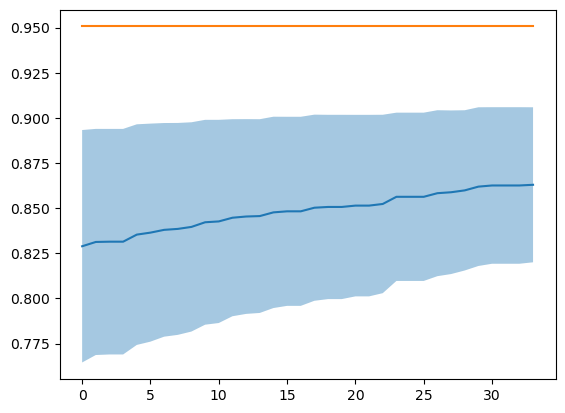

In [59]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(data, columns = ['best', 'mean', 'std'])

plt.fill_between(df.index, df['mean']-df['std'], df['mean'] + df['std'], alpha=0.4)
plt.plot(df['mean'])
plt.plot(df['best'])

# Outputs

In [60]:
df_safe = library.molecules
df_safe.head()

,smiles,score
0,Cc1[nH]c(=O)sc1C(=O)NCCNCc1cc(F)ccc1F,0.950644
1,Cc1[nH]c(=O)sc1C(=O)NCCCCc1cc(F)ccc1F,0.942134
2,Cc1[nH]c(=O)sc1C(=O)Cc1cc(F)ccc1F,0.933970
3,Cc1[nH]c(=O)sc1C(=O)Nc1cc(F)ccc1F,0.928531
4,Cc1[nH]c(=O)sc1C(=O)N([N-])Cc1cc(F)ccc1F,0.927576


In [61]:
len(df_safe)

1321

Cc1[nH]c(=O)sc1C(=O)NCCCCc1cc(F)ccc1F


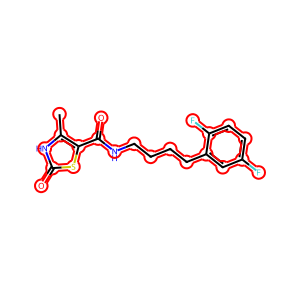

In [62]:
import safe as sf
print(df_safe.iloc[1,0])
sf.to_image(df_safe.iloc[1,0])


In [63]:
len(df_safe)

1321

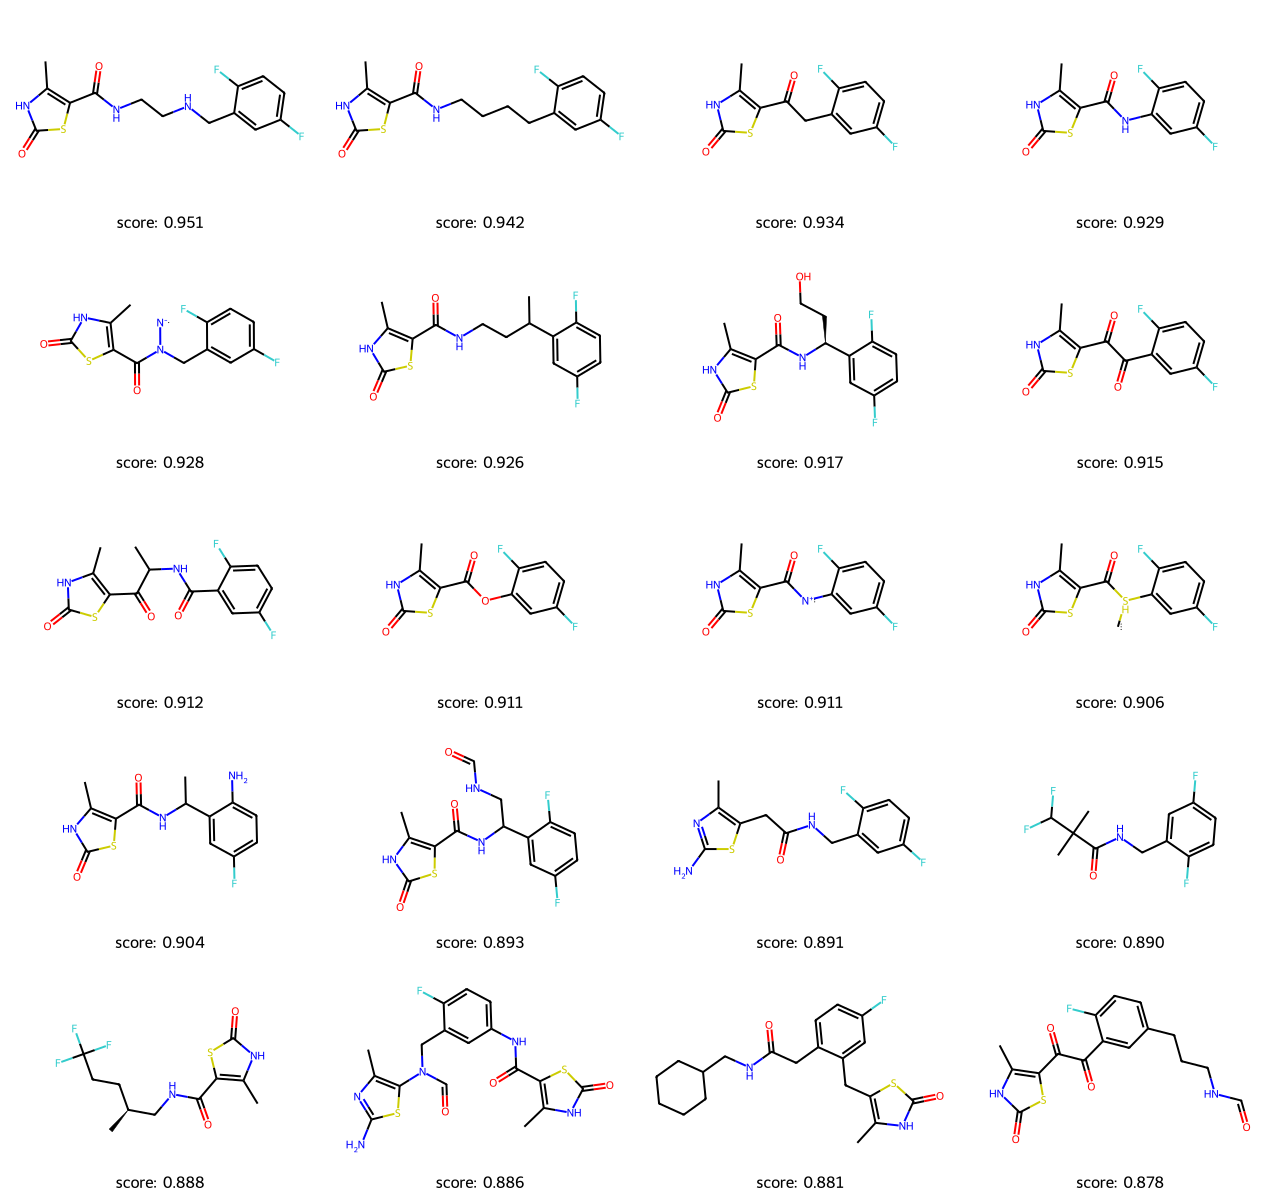

In [64]:
from rdkit.Chem import Draw
from rdkit import Chem
#select first 20
df_to_show = df_safe.iloc[0:20].copy()

#vis
ms = [Chem.MolFromSmiles(row['smiles']) for index, row in df_to_show.iterrows()]
legends = ['score: {:.3f}'.format(row['score']) for index, row in df_to_show.iterrows()]
#['score ' + str(row['score']) for index, row in df_to_show.iterrows()]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(320, 240), legends=legends)


In [45]:
#df_safe.to_csv('../../data/processed/genmol/KRS_moo_R2_lower_sim.csv')